### 2. Modelo Logístico con Flujo Migratorio Externo ($\mu$)
Se ajusta la serie histórica post-revolucionaria (1930–2025) mediante mínimos cuadrados no lineales (`scipy.optimize.curve_fit`) para estimar la tasa intrínseca $r$ y la capacidad de carga $K$ de cada entidad. Posteriormente, se integra numéricamente (`scipy.integrate.solve_ivp`) la ecuación diferencial entre 2025 y 2035 comparando el escenario con migración activa frente al escenario sin migración ($\mu = 0$):

$$\frac{dP}{dt} = rP\left(1 - \frac{P}{K}\right) + \mu$$

donde $\mu$ $[\text{hab/año}]$ representa el flujo migratorio anualizado de cada estado:

* $\mu > 0$ representa un estado receptor de migración.
* $\mu < 0$ representa un estado emisor migratorio.
* $\mu = 0$ representa un estado sin flujo migratorio.

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit

# Cargar el Parquet limpio desde data/processed/
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
RUTA_PARQUET = BASE_DIR / "data" / "processed" / "demografia_inegi_estatal.parquet"

df = pd.read_parquet(RUTA_PARQUET)
print(f"Total de registros cargados: {len(df)}")
df.head()

Total de registros cargados: 544


,Anio,Poblacion_Total,Densidad_Pob,Pob_15_a_64,Saldo_Migratorio_Interno,CVE_ENT,Entidad,Fecha
0,1900,NaN,18.3,NaN,NaN,01,Aguascalientes,1900-01-01
1,1910,120511.0,15.7,NaN,NaN,01,Aguascalientes,1910-01-01
2,1921,107581.0,16.6,NaN,NaN,01,Aguascalientes,1921-01-01
3,1930,132900.0,20.5,NaN,NaN,01,Aguascalientes,1930-01-01
4,1940,161693.0,25.0,NaN,NaN,01,Aguascalientes,1940-01-01


In [ ]:
def modelo_logistico(t, K, r, P0, t0):
    """Ecuación logística con P0 libre para absorber ruido histórico inicial."""
    return K / (1.0 + ((K - P0) / P0) * np.exp(-r * (t - t0)))

def proyectar_estado(df_estado, anios_futuros=[2030, 2035]):
    """Ajusta K, r y P0 desde 1930 dando mayor peso a las últimas décadas."""
    # Filtramos desde 1930 para eliminar la caída anómala de la Revolución (1910-1921)
    df_val = df_estado[df_estado["Anio"] >= 1930].dropna(subset=["Poblacion_Total"]).sort_values("Anio")
    
    t_data = df_val["Anio"].values.astype(float)
    p_data = df_val["Poblacion_Total"].values.astype(float)
    
    t0 = t_data[0]
    p_min = p_data[0]
    p_max = p_data.max()
    
    def func_ajuste(t, K, r, P0):
        return modelo_logistico(t, K, r, P0, t0)
    
    # Mayor peso estadístico (menor sigma) a los censos recientes (2000-2025)
    sigma_pesos = np.where(t_data >= 2000, 0.25, 1.0)
    
    # Semillas iniciales: K = 1.5 veces pob actual, r = 0.03, P0 = pob en 1930
    p0_guess = [p_max * 1.5, 0.03, p_min]
    # Cotas: K entre 1.02*p_max y 4.5*p_max; r entre 0.005 y 0.10; P0 flexible
    bounds = ([p_max * 1.02, 0.005, p_min * 0.3], [p_max * 4.5, 0.10, p_min * 1.8])
    
    popt, _ = curve_fit(
        func_ajuste, t_data, p_data, p0=p0_guess, 
        sigma=sigma_pesos, bounds=bounds, maxfev=20000
    )
    K_opt, r_opt, P0_opt = popt
    
    # Wrapper final evaluable solo con t
    curva_final = lambda t: func_ajuste(t, K_opt, r_opt, P0_opt)
    
    fila_2025 = df_val[df_val["Anio"] == 2025].iloc[0]
    superficie_km2 = fila_2025["Poblacion_Total"] / fila_2025["Densidad_Pob"]
    prop_15_64 = fila_2025["Pob_15_a_64"] / fila_2025["Poblacion_Total"]
    
    nuevas_filas = []
    for anio in anios_futuros:
        pob_proy = float(curva_final(anio))
        nuevas_filas.append({
            "Anio": int(anio),
            "Fecha": pd.to_datetime(f"{anio}-01-01"),
            "CVE_ENT": fila_2025["CVE_ENT"],
            "Entidad": fila_2025["Entidad"],
            "Poblacion_Total": round(pob_proy, 0),
            "Densidad_Pob": round(pob_proy / superficie_km2, 4),
            "Pob_15_a_64": round(pob_proy * prop_15_64, 0),
            "Saldo_Migratorio_Interno": np.nan,
            "Tipo_Dato": "Proyección Logística",
            "K_Capacidad": round(K_opt, 0),
            "r_Tasa": round(r_opt, 5)
        })
        
    return pd.DataFrame(nuevas_filas), K_opt, r_opt, curva_final

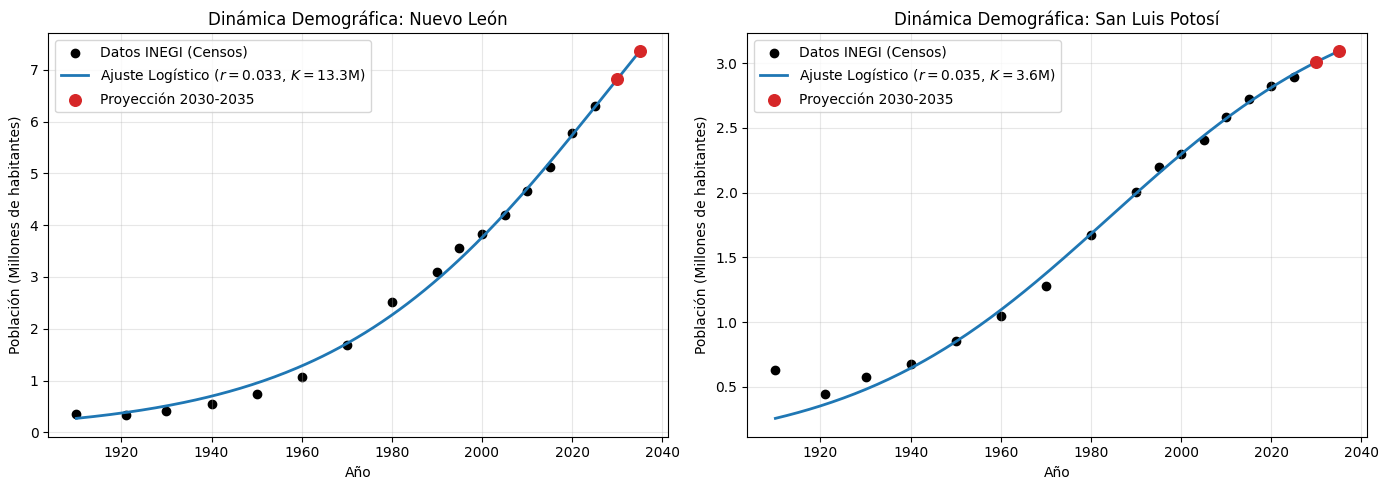

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
estados_ejemplo = [("19", "Nuevo León"), ("24", "San Luis Potosí")]

for ax, (cve, nombre) in zip(axes, estados_ejemplo):
    df_est = df[df["CVE_ENT"] == cve]
    df_proy, K_opt, r_opt, func_ajuste = proyectar_estado(df_est)

    t_curva = np.linspace(1910, 2035, 200)
    ax.scatter(
        df_est["Anio"],
        df_est["Poblacion_Total"] / 1e6,
        color="black",
        label="Datos INEGI (Censos)",
    )
    ax.plot(
        t_curva,
        func_ajuste(t_curva) / 1e6,
        color="tab:blue",
        lw=2,
        label=f"Ajuste Logístico ($r={r_opt:.3f}$, $K={K_opt/1e6:.1f}$M)",
    )
    ax.scatter(
        df_proy["Anio"],
        df_proy["Poblacion_Total"] / 1e6,
        color="tab:red",
        s=70,
        zorder=5,
        label="Proyección 2030-2035",
    )

    ax.set_title(f"Dinámica Demográfica: {nombre}")
    ax.set_xlabel("Año")
    ax.set_ylabel("Población (Millones de habitantes)")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
df["Tipo_Dato"] = "Histórico Censal"
df["K_Capacidad"] = np.nan
df["r_Tasa"] = np.nan

proyecciones = []
for cve, grupo in df.groupby("CVE_ENT"):
    df_proy, K_opt, r_opt, _ = proyectar_estado(grupo)
    # Asignar K y r también a las filas históricas del estado para consultarlos en Power BI
    df.loc[df["CVE_ENT"] == cve, "K_Capacidad"] = round(K_opt, 0)
    df.loc[df["CVE_ENT"] == cve, "r_Tasa"] = round(r_opt, 5)
    proyecciones.append(df_proy)

df_completo = pd.concat([df] + proyecciones, ignore_index=True).sort_values(
    ["CVE_ENT", "Anio"]
)

# Comparativa 2025 vs 2035 por estado
pob_2025 = df_completo[df_completo["Anio"] == 2025].set_index("Entidad")[
    "Poblacion_Total"
]
pob_2035 = df_completo[df_completo["Anio"] == 2035].set_index("Entidad")[
    "Poblacion_Total"
]

resumen_10_anios = pd.DataFrame({
    "Pob_2025": pob_2025,
    "Pob_2035_Proyectada": pob_2035,
    "Crecimiento_Neto_Hab": pob_2035 - pob_2025,
    "Crecimiento_Porcentual_%": ((pob_2035 - pob_2025) / pob_2025) * 100,
}).sort_values("Crecimiento_Porcentual_%", ascending=False)

print("Top 10 estados con mayor presión demográfica proyectada (2025 -> 2035):")
resumen_10_anios.head(10)

Top 10 estados con mayor presión demográfica proyectada (2025 -> 2035):


,Pob_2025,Pob_2035_Proyectada,Crecimiento_Neto_Hab,Crecimiento_Porcentual_%
Entidad,,,,
Baja California Sur,961514.0,1209400.0,247886.0,25.780800
Querétaro,2606836.0,3209650.0,602814.0,23.124355
Quintana Roo,2100792.0,2567982.0,467190.0,22.238756
Nuevo León,6291899.0,7357273.0,1065374.0,16.932471
Hidalgo,3245595.0,3747813.0,502218.0,15.473835
Yucatán,2506448.0,2849852.0,343404.0,13.700823
Aguascalientes,1539174.0,1743217.0,204043.0,13.256656
Nayarit,1299075.0,1456240.0,157165.0,12.098224
Coahuila,3415128.0,3818919.0,403791.0,11.823598


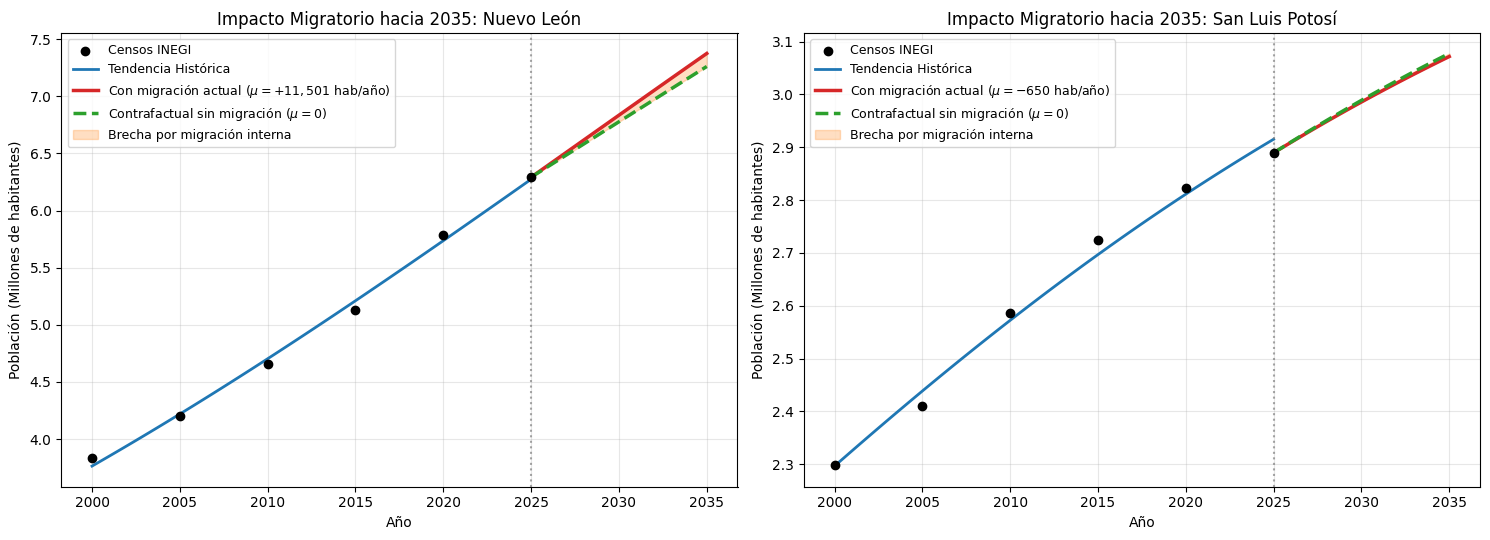

In [ ]:
from scipy.integrate import solve_ivp

def simular_escenarios_migracion(df_estado, K_eff, r_opt, func_logistica):
    """
    Integra la EDO logística entre 2025 y 2035 comparando la tendencia actual
    contra el escenario contrafactual sin migración (mu = 0).
    """
    df_val = df_estado.sort_values("Anio")
    pob_2025 = float(df_val[df_val["Anio"] == 2025]["Poblacion_Total"].iloc[0])
    
    # Extraer el último Saldo Migratorio disponible (ya viene en habitantes quinquenales)
    saldos = df_val["Saldo_Migratorio_Interno"].dropna()
    saldo_quinquenal = float(saldos.iloc[-1]) if not saldos.empty else 0.0
    
    # Flujo anual mu [Habitantes / Año] = Saldo de 5 años / 5
    mu_anual = saldo_quinquenal / 5.0
    
    # EDO: dP/dt = crecimiento_logistico_efectivo + delta_mu
    def edo_poblacion(t, P, delta_mu):
        P_actual = max(P[0], 1.0) # Evita poblaciones negativas numéricas
        dP_base = r_opt * P_actual * (1.0 - P_actual / K_eff)
        return [dP_base + delta_mu]

    t_eval = np.linspace(2025, 2035, 50)
    
    # 1. Escenario Base (Continúa el flujo migratorio actual)
    sol_base = solve_ivp(edo_poblacion, [2025, 2035], [pob_2025], args=(0.0,), t_eval=t_eval)
    # 2. Escenario Contrafactual Sin Migración (Apagamos el flujo restando mu_anual)
    sol_sin_mig = solve_ivp(edo_poblacion, [2025, 2035], [pob_2025], args=(-mu_anual,), t_eval=t_eval)
    
    return t_eval, sol_base.y[0], sol_sin_mig.y[0], mu_anual

# --- GRAFICAR ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
estados_ejemplo = [("19", "Nuevo León"), ("24", "San Luis Potosí")]

for ax, (cve, nombre) in zip(axes, estados_ejemplo):
    df_est = df[df["CVE_ENT"] == cve]
    
    # 1. Ajuste logístico base
    df_proy, K_opt, r_opt, curva_final = proyectar_estado(df_est)
    
    # 2. Simulación de EDO con y sin migración
    t_sim, p_con_mig, p_sin_mig, mu_anual = simular_escenarios_migracion(
        df_est, K_opt, r_opt, curva_final
    )
    
    df_zoom = df_est[df_est["Anio"] >= 2000]
    t_hist = np.linspace(2000, 2025, 100)
    
    # Datos históricos y curva ajustada
    ax.scatter(
        df_zoom["Anio"],
        df_zoom["Poblacion_Total"] / 1e6,
        color="black",
        zorder=5,
        label="Censos INEGI",
    )
    ax.plot(
        t_hist,
        curva_final(t_hist) / 1e6,
        color="tab:blue",
        lw=2,
        label="Tendencia Histórica",
    )
    
    # Trayectorias 2025-2035 (usando raw strings r"..." para evitar el SyntaxWarning de \mu)
    ax.plot(
        t_sim,
        p_con_mig / 1e6,
        color="tab:red",
        lw=2.5,
        label=rf"Con migración actual ($\mu = {mu_anual:+,.0f}$ hab/año)",
    )
    ax.plot(
        t_sim,
        p_sin_mig / 1e6,
        color="tab:green",
        lw=2.5,
        linestyle="--",
        label=r"Contrafactual sin migración ($\mu = 0$)",
    )
    
    # Área entre curvas
    ax.fill_between(
        t_sim,
        p_con_mig / 1e6,
        p_sin_mig / 1e6,
        color="tab:orange",
        alpha=0.25,
        label="Brecha por migración interna",
    )
    
    ax.axvline(2025, color="gray", linestyle=":", alpha=0.7)
    ax.set_title(f"Impacto Migratorio hacia 2035: {nombre}")
    ax.set_xlabel("Año")
    ax.set_ylabel("Población (Millones de habitantes)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper left", fontsize=9)

plt.tight_layout()
plt.show()